# 01 · Understanding the Fraud Landscape

**Credit Card Fraud Analytics & Investigation Optimization**  
*Research notebook · data understanding, quality, rare-event prevalence and descriptive fraud exposure*

> **Central question:** How are labeled fraudulent transactions distributed across transaction amount, elapsed time and anonymized features—and why might case frequency differ from recorded fraudulent transaction value?

**Scope:** descriptive exploration of the **original, duplicate-retained ULB dataset**. This notebook does not fit models, choose thresholds, perform confirmatory hypothesis testing, or quantify realized financial loss.

**Research questions**

- **RQ1:** How rare is fraud, and what does that imply for evaluation?
- **RQ2:** Do fraud *case counts* and *recorded fraudulent value* concentrate in the same transaction-amount segments?
- **RQ3:** How does observed fraud prevalence vary across elapsed-time windows?
- **RQ4:** Do anonymized features show different class-conditional distributions?

**Method:** load the project's previously validated, read-only EDA and business report artifacts. No source data or report is modified.

## 1 · Reproducible setup and evidence contract

Run this notebook from the repository root **or** from `notebooks/`. It uses local files created by `src.data_cleaner`, `src.analysis`, `src.business_analysis`, and `src.visualization`. If the reports are missing, run the existing project modules from the repository root in that order. The code below deliberately fails rather than filling missing evidence with example data.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for folder in (current, *current.parents):
        if (folder / "reports/tables/eda/class_balance.csv").is_file() and (folder / "reports/tables/data_quality/quality_summary.json").is_file():
            return folder
    raise FileNotFoundError(
        "Project reports not found. From the repository root, run: "
        "python -m src.data_cleaner; python -m src.analysis; "
        "python -m src.business_analysis; python -m src.visualization --format png"
    )

ROOT = find_project_root()
EDA = ROOT / "reports/tables/eda"
BUSINESS = ROOT / "reports/tables/business"
QUALITY = ROOT / "reports/tables/data_quality/quality_summary.json"
FIGURES = ROOT / "reports/figures/eda"

def report_csv(folder: Path, filename: str, required: set[str]) -> pd.DataFrame:
    path = folder / filename
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path.relative_to(ROOT)}. Generate the corresponding analysis reports first.")
    frame = pd.read_csv(path)
    missing = required.difference(frame.columns)
    if missing:
        raise ValueError(f"{filename} is missing expected columns: {sorted(missing)}")
    return frame

print("Project root:", ROOT)
print("Notebook mode: read-only; source population = original dataset, exact duplicates retained")

Project root: E:\DataAnalytics\Projects\Credit_Card_Fraud_Analytics
Notebook mode: read-only; source population = original dataset, exact duplicates retained


### Dataset and semantic boundaries

The ULB dataset contains **31 numerical columns**: `Time`, `Amount`, `V1`–`V28` and binary `Class`. `Class=1` denotes labeled fraud; `Class=0` denotes labeled legitimate transactions. `Time` is **elapsed seconds from the first recorded transaction**, not a time-zone-aware date or clock hour. The `V` features are anonymized PCA components; their original business meanings are unavailable. `Amount` has **no independently verified currency**.

We retain the original population in this notebook because dropping identical rows changes both the denominator and the observed fraud total. Exact duplicates are **audited**, not automatically called erroneous transactions. Deduplicated modeling experiments belong to Notebook 03.

In [2]:
quality = json.loads(QUALITY.read_text(encoding="utf-8"))
q = quality["after"]
quality_view = pd.DataFrame([
    ("Original rows", q["rows"]),
    ("Columns", q["columns"]),
    ("Missing cells", q["missing_cells"]),
    ("Non-finite cells", q["non_finite_cells"]),
    ("Exact duplicate rows beyond first occurrence", q["duplicate_rows_excluding_first"]),
    ("Duplicate fraud rows", q["duplicate_fraud_rows"]),
    ("Zero-amount transactions", q["zero_amount_rows"]),
    ("Negative-amount rows", q["negative_amount_rows"]),
    ("Elapsed-time span (hours)", (q["time_max_seconds"] - q["time_min_seconds"]) / 3600),
], columns=["Data-quality measure", "Observed value"])
display(quality_view)
assert quality["duplicate_policy"] == "keep", "EDA notebook requires duplicate-retained cleaning reports."
assert quality["original_units_retained"], "Amount/Time were transformed unexpectedly."
assert q["rows"] == 284807 and q["columns"] == 31, "Unexpected dataset version: review provenance before interpreting outputs."
assert q["missing_cells"] == 0 and q["non_finite_cells"] == 0
print("PASS — quality report is the expected original-population snapshot")

,Data-quality measure,Observed value
0,Original rows,"284,807.0000"
1,Columns,31.0000
2,Missing cells,0.0000
3,Non-finite cells,0.0000
4,Exact duplicate rows beyond first occurrence,"1,081.0000"
5,Duplicate fraud rows,19.0000
6,Zero-amount transactions,"1,825.0000"
7,Negative-amount rows,0.0000
8,Elapsed-time span (hours),47.9978


PASS — quality report is the expected original-population snapshot


**Interpretation.** This snapshot contains 1,081 exact duplicate rows, including 19 labeled fraud rows, and no missing values. Because there is no transaction identifier or customer context, we cannot determine whether each identical row is a faulty duplicate or a valid repeated transaction. The duplicate decision is therefore a documented **sensitivity assumption**, not an unexamined cleaning step.

## 2 · RQ1 — Why rare-event prevalence changes the analytical problem

Start with **class prevalence**, not overall classification accuracy. A model that always predicts "legitimate" can appear highly accurate in this dataset while identifying no fraud cases.

In [3]:
balance = report_csv(EDA, "class_balance.csv", {"class", "class_name", "transaction_count", "percent_of_transactions"})
assert set(balance["class"].astype(int)) == {0, 1}
transactions = int(balance.transaction_count.sum())
frauds = int(balance.loc[balance["class"].eq(1), "transaction_count"].iloc[0])
legitimate = int(balance.loc[balance["class"].eq(0), "transaction_count"].iloc[0])
fraud_prevalence = 100 * frauds / transactions
assert transactions == int(q["rows"]) and frauds == int(q["fraud_rows"])
assert legitimate == int(q["legitimate_rows"])
assert np.isclose(balance.percent_of_transactions.sum(), 100, atol=1e-8)
display(balance.style.format({"transaction_count": "{:,.0f}", "percent_of_transactions": "{:.4f}%"}))
print(f"Fraud prevalence: {fraud_prevalence:.4f}% | Legitimate-to-fraud ratio: {legitimate / frauds:.1f}:1")
print(f"Always-legitimate accuracy: {100*(1-frauds/transactions):.4f}% | Fraud recall: 0.0%")

,class,class_name,transaction_count,percent_of_transactions
0,0,Legitimate,"284,315",99.8273%
1,1,Fraud,492,0.1727%


Fraud prevalence: 0.1727% | Legitimate-to-fraud ratio: 577.9:1
Always-legitimate accuracy: 99.8273% | Fraud recall: 0.0%


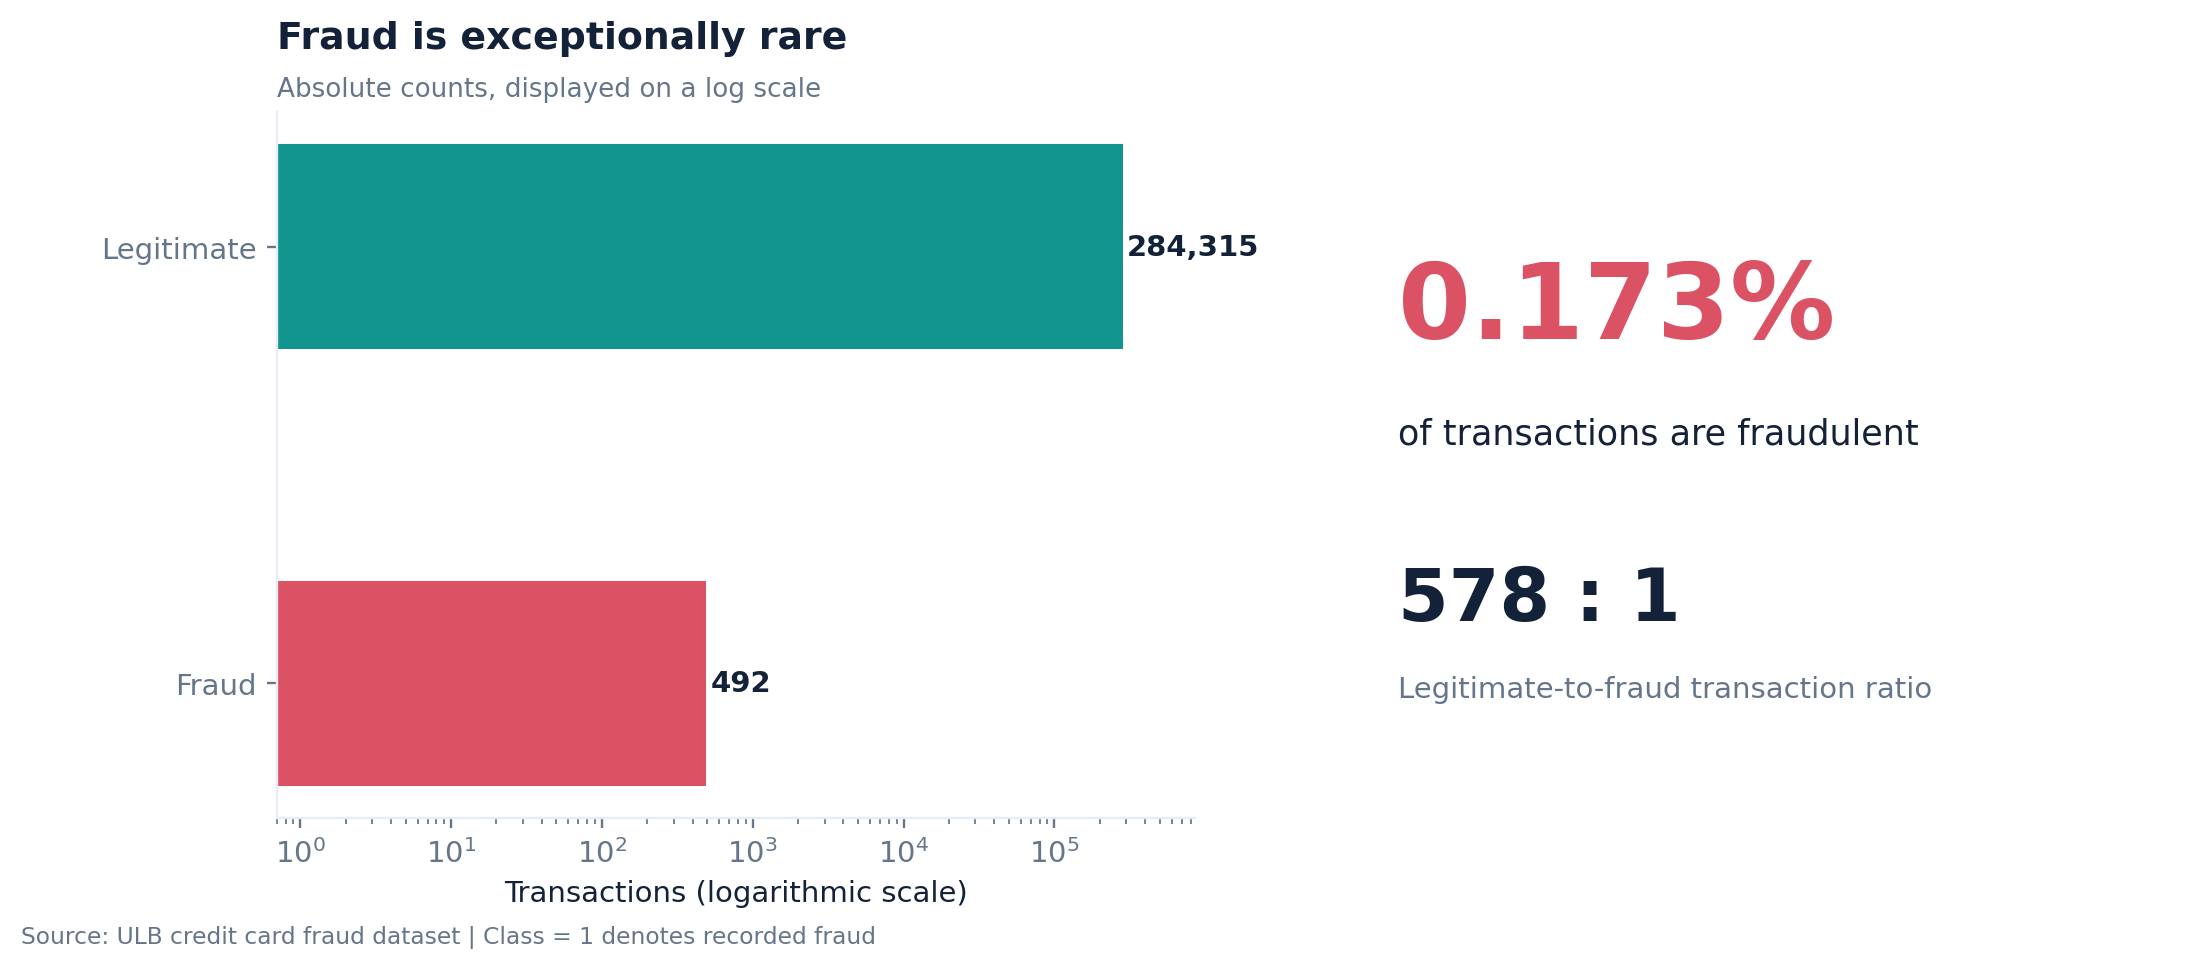

*Figure 1 · Original dataset: severe class imbalance. A high accuracy baseline could still catch no fraud.*

In [4]:
def show_verified_figure(filename: str, caption: str) -> None:
    image_path = FIGURES / filename
    if not image_path.is_file():
        raise FileNotFoundError(f"Missing EDA figure: {image_path.relative_to(ROOT)}. Run python -m src.visualization --format png")
    display(Image(filename=str(image_path), width=1050))
    display(Markdown(f"*{caption}*"))

show_verified_figure("01_class_imbalance.png", "Figure 1 · Original dataset: severe class imbalance. A high accuracy baseline could still catch no fraud.")

**RQ1 answer.** In the original dataset, 492 of 284,807 transactions are labeled fraud (**0.1727%**). Conventional accuracy can obscure failure on the minority class; later experiments therefore emphasize precision, recall and average precision (PR-AUC). This is a **measurement decision**, not evidence that any particular model is deployable.

## 3 · RQ2 — Fraud frequency versus recorded financial exposure

This section is the notebook's main analytical contribution. We first characterize amount distributions by class, then compare **fraud-case share** against **fraudulent-value share** within the same amount bands.

The published bands were produced with the project's original `pandas.qcut` methodology. We **load those saved bands** rather than recomputing boundaries differently.

In [5]:
by_class = report_csv(EDA, "amount_by_class.csv", {"Class", "txn_count", "total_amount", "mean_amount", "median_amount", "class_name"})
display(by_class[["class_name", "txn_count", "total_amount", "mean_amount", "median_amount"]].style.format({
    "txn_count": "{:,.0f}", "total_amount": "{:,.2f}", "mean_amount": "{:,.2f}", "median_amount": "{:,.2f}"}))
assert int(by_class.txn_count.sum()) == transactions
recorded_fraud_value = float(by_class.loc[by_class["Class"].eq(1), "total_amount"].iloc[0])
assert np.isclose(recorded_fraud_value, float(q["fraud_transaction_amount"]), atol=.01)
print(f"Recorded fraudulent transaction value: {recorded_fraud_value:,.2f} dataset amount units (NOT verified losses).")

,class_name,txn_count,total_amount,mean_amount,median_amount
0,Legitimate,"284,315","25,102,462.04",88.29,22.00
1,Fraud,492,"60,127.97",122.21,9.25


Recorded fraudulent transaction value: 60,127.97 dataset amount units (NOT verified losses).


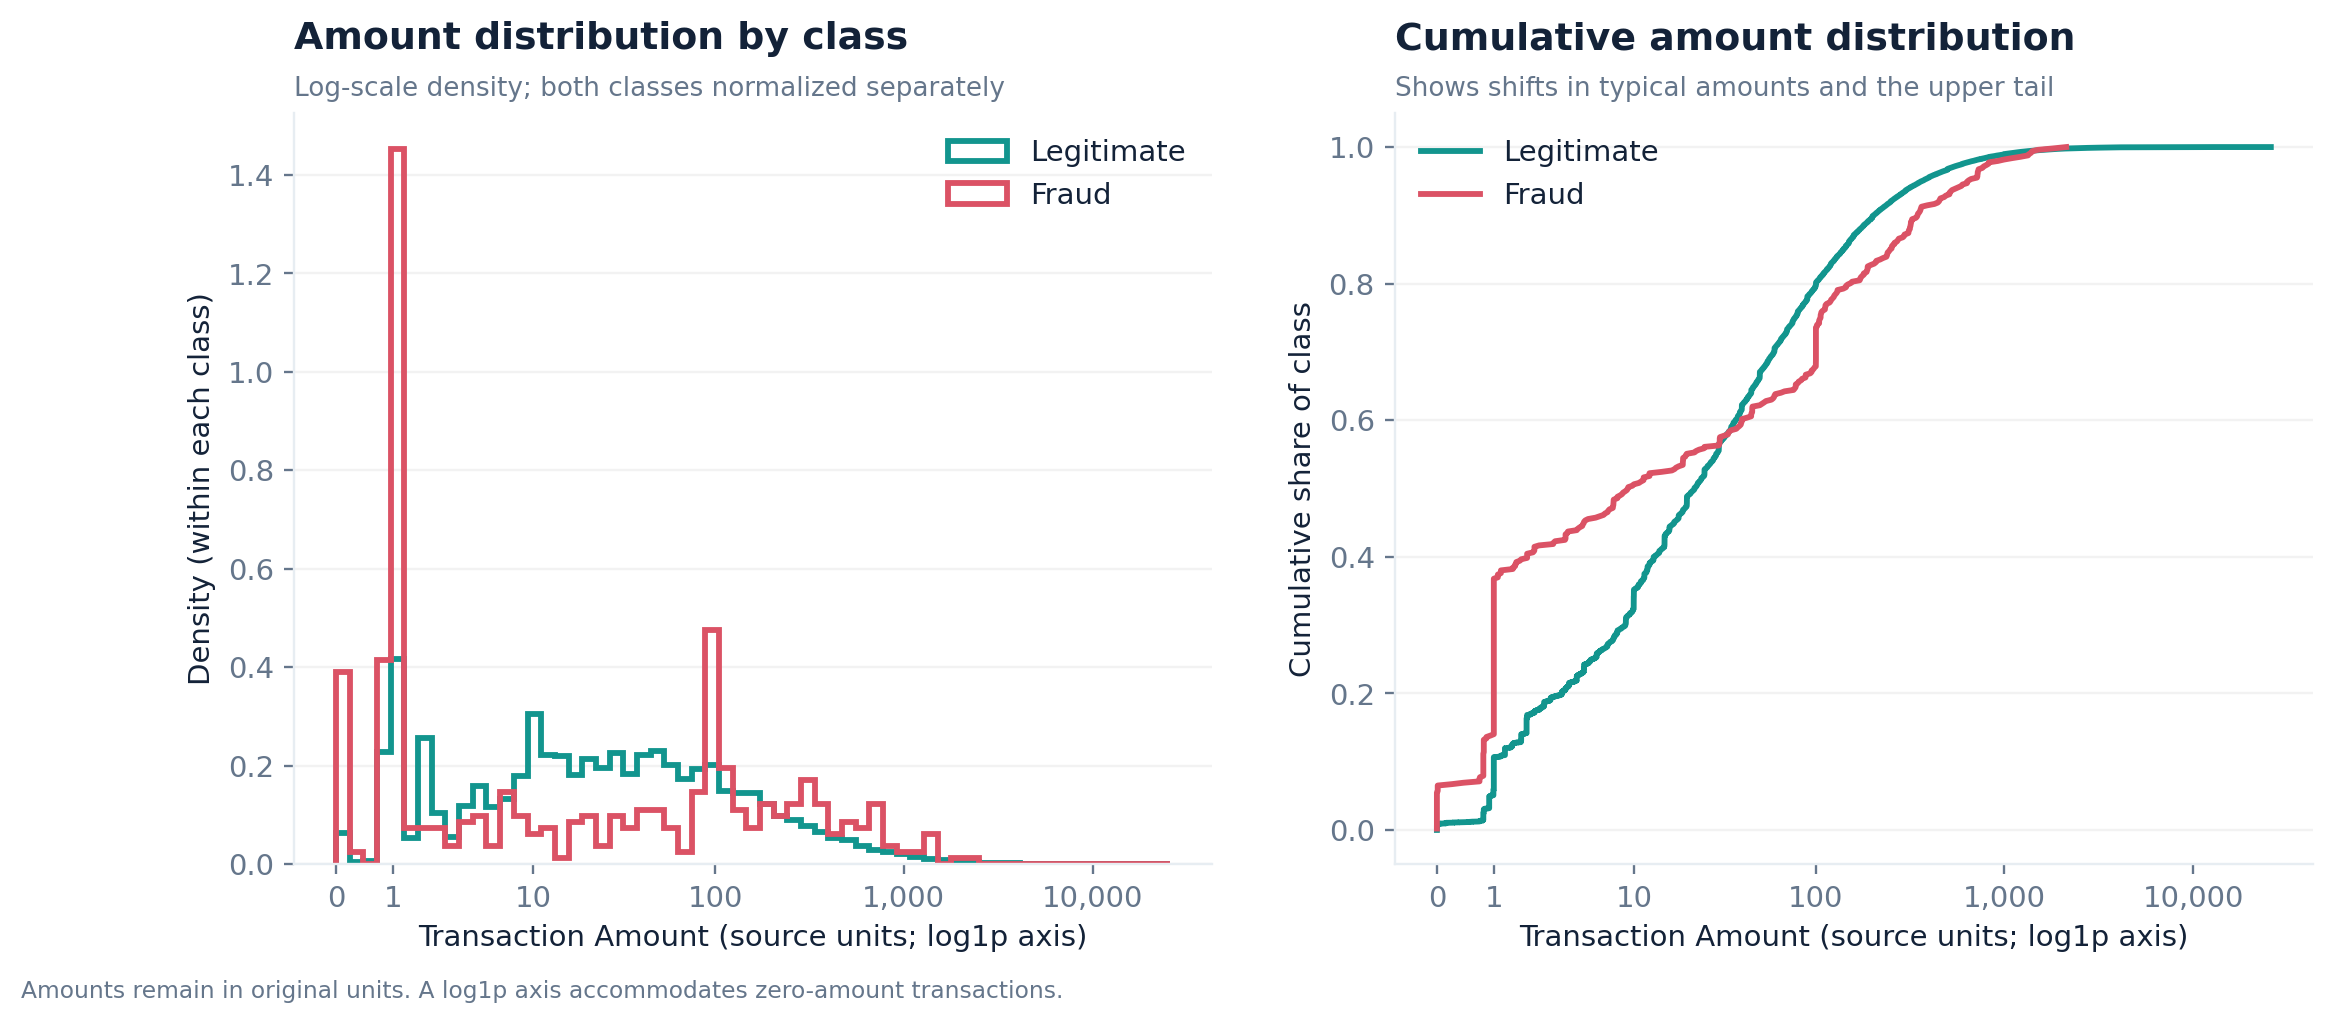

*Figure 2 · Transaction amounts are skewed. Read transformed/log axes carefully; the original monetary units are preserved in tables.*

In [6]:
show_verified_figure("02_amount_distributions.png", "Figure 2 · Transaction amounts are skewed. Read transformed/log axes carefully; the original monetary units are preserved in tables.")

**Amount insight.** Fraudulent transactions have a **lower median amount** (9.25) than legitimate transactions (22.00), yet a **higher mean** (122.21 versus 88.29). This is a useful reminder that skewed distributions can make average amounts misleading. It does **not** mean transaction amount causes fraud.

In [7]:
bands = report_csv(EDA, "fraud_by_amount_band.csv", {
    "decile", "total_txns", "fraud_txns", "fraud_amount", "fraud_rate_pct",
    "share_of_fraud_cases_pct", "share_of_fraud_value_pct", "min_amount", "max_amount"
}).sort_values("decile").reset_index(drop=True)
assert len(bands) == 10 and bands.decile.astype(int).tolist() == list(range(10))
assert int(bands.total_txns.sum()) == transactions
assert int(bands.fraud_txns.sum()) == frauds
assert np.isclose(bands.fraud_amount.sum(), recorded_fraud_value, atol=.01)
assert np.isclose(bands.share_of_fraud_cases_pct.sum(), 100, atol=.01)
assert np.isclose(bands.share_of_fraud_value_pct.sum(), 100, atol=.01)
bands_display = bands[["decile", "total_txns", "fraud_txns", "fraud_rate_pct", "fraud_amount", "share_of_fraud_cases_pct", "share_of_fraud_value_pct"]].copy()
bands_display["decile"] = bands_display.decile.map(lambda x: f"Q{int(x)+1:02d}")
display(bands_display.style.format({
    "total_txns": "{:,.0f}", "fraud_txns": "{:,.0f}", "fraud_rate_pct": "{:.3f}%",
    "fraud_amount": "{:,.2f}", "share_of_fraud_cases_pct": "{:.2f}%", "share_of_fraud_value_pct": "{:.2f}%"
}))
lo, hi = bands.iloc[0], bands.iloc[-1]
print(f"Lowest band: {int(lo.fraud_txns)} fraud cases ({lo.share_of_fraud_cases_pct:.2f}%), "
      f"{lo.share_of_fraud_value_pct:.2f}% fraudulent value.")
print(f"Highest band: {int(hi.fraud_txns)} fraud cases ({hi.share_of_fraud_cases_pct:.2f}%), "
      f"{hi.share_of_fraud_value_pct:.2f}% fraudulent value.")

,decile,total_txns,fraud_txns,fraud_rate_pct,fraud_amount,share_of_fraud_cases_pct,share_of_fraud_value_pct
0,Q01,"30,492",181,0.594%,139.56,36.79%,0.23%
1,Q02,"26,473",27,0.102%,51.14,5.49%,0.09%
2,Q03,"28,559",36,0.126%,220.76,7.32%,0.37%
3,Q04,"28,405",13,0.046%,140.24,2.64%,0.23%
4,Q05,"28,714",14,0.049%,256.64,2.85%,0.43%
5,Q06,"28,375",17,0.060%,497.81,3.46%,0.83%
6,Q07,"28,366",24,0.085%,"1,102.20",4.88%,1.83%
7,Q08,"28,915",50,0.173%,"4,610.91",10.16%,7.67%
8,Q09,"28,050",45,0.160%,"6,142.82",9.15%,10.22%
9,Q10,"28,458",85,0.299%,"46,965.89",17.28%,78.11%


Lowest band: 181 fraud cases (36.79%), 0.23% fraudulent value.
Highest band: 85 fraud cases (17.28%), 78.11% fraudulent value.


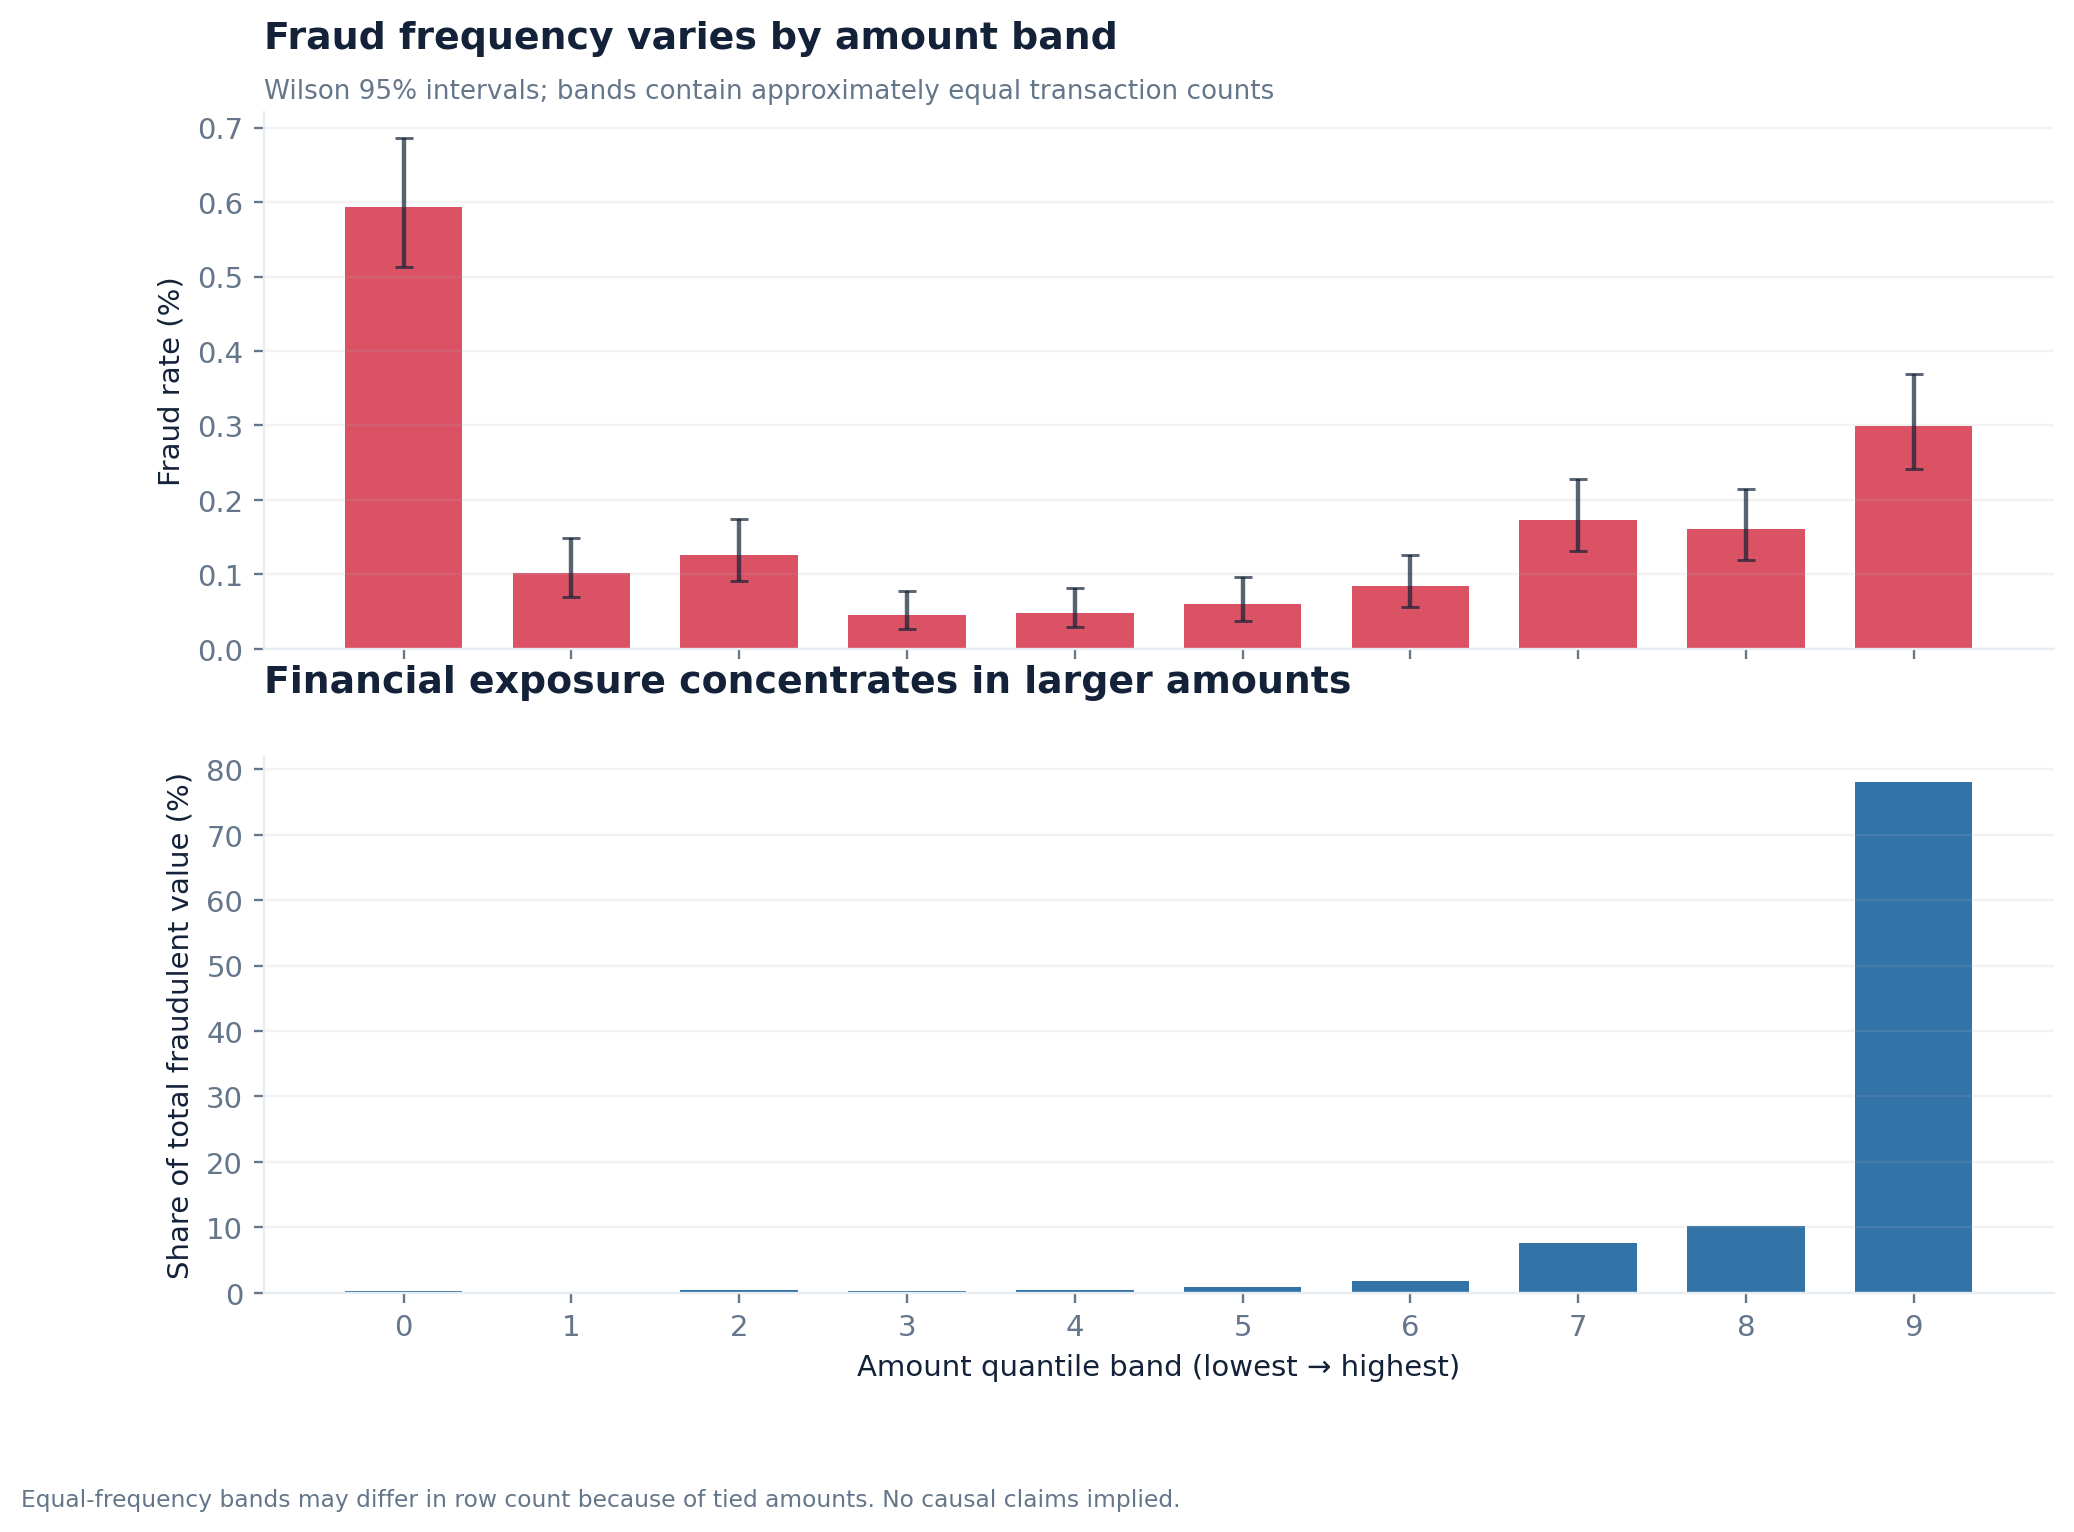

*Figure 3 · Band-level fraud rates and recorded fraudulent-value shares answer different questions. The figure includes interval estimates for rates.*

In [8]:
show_verified_figure("04_fraud_rate_vs_fraud_value.png", "Figure 3 · Band-level fraud rates and recorded fraudulent-value shares answer different questions. The figure includes interval estimates for rates.")

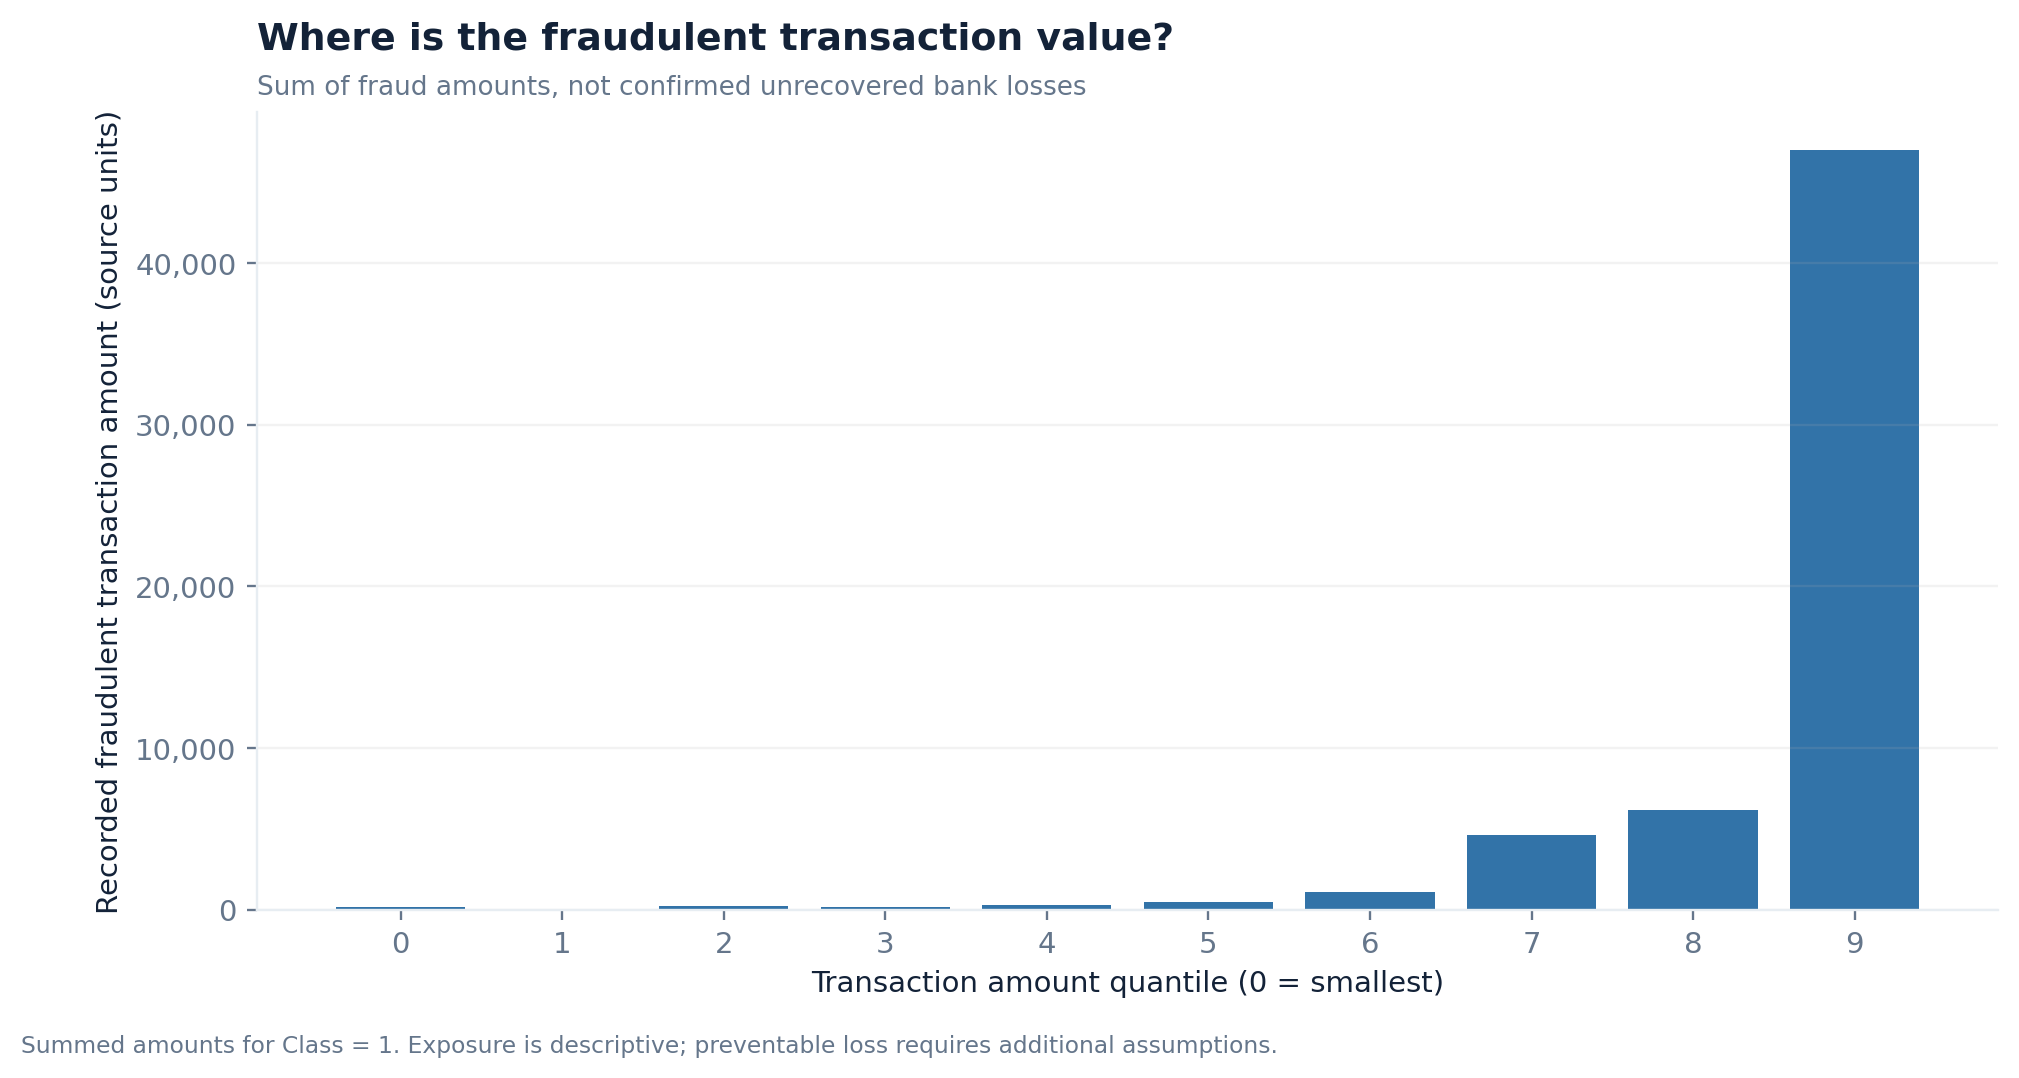

*Figure 4 · Absolute recorded fraudulent value by amount band. The largest band dominates the total; small-band values must not be mistaken for zero.*

In [9]:
show_verified_figure("05_fraud_amount_by_band.png", "Figure 4 · Absolute recorded fraudulent value by amount band. The largest band dominates the total; small-band values must not be mistaken for zero.")

**RQ2 answer.** The **lowest amount band** contains approximately **36.79% of fraud cases**, but just **0.23% of recorded fraudulent value**. The **highest band** contains approximately **17.28% of fraud cases**, yet **78.11% of the recorded fraudulent value**. 

These percentages have different denominators: *all observed fraud cases* versus *all recorded value on fraud-labeled transactions*. That distinction motivates fraud-*value* recall in the ML and investigation notebooks. **The amount is not equivalent to a confirmed bank loss or recoverable amount.**

## 4 · Zero-amount records: an important descriptive edge case

Zero-amount records are easy to overlook in monetary charts. They can have nonzero *fraud prevalence* while contributing zero to *recorded transaction value*. Their underlying purpose is unknown.

In [10]:
zero = report_csv(EDA, "zero_amount_analysis.csv", {"amount_segment", "total_txns", "fraud_txns", "fraud_rate_pct"})
assert int(zero.total_txns.sum()) == transactions
assert int(zero.fraud_txns.sum()) == frauds
display(zero.style.format({"total_txns": "{:,.0f}", "fraud_txns": "{:,.0f}", "fraud_rate_pct": "{:.4f}%"}))
print("Descriptive comparison only. Statistical testing and confidence intervals belong to Notebook 02.")

,amount_segment,total_txns,fraud_txns,fraud_rate_pct,fraud_rate_ci_low_pct,fraud_rate_ci_high_pct
0,Positive amount,"282,982",465,0.1643%,0.150060,0.179936
1,Zero amount,"1,825",27,1.4795%,1.018744,2.143994


Descriptive comparison only. Statistical testing and confidence intervals belong to Notebook 02.


## 5 · RQ3 — Elapsed-time variation, not daily seasonality

The dataset spans roughly 48 **elapsed hours**. We explore four-hour windows, but do not assume these are local clock-hour buckets, weekdays, or stable recurring patterns.

In [11]:
time_segments = report_csv(EDA, "fraud_by_time_interval.csv", {
    "segment", "total_txns", "fraud_txns", "from_elapsed_hour", "to_elapsed_hour", "fraud_rate_pct"
}).sort_values("segment")
assert int(time_segments.total_txns.sum()) == transactions
assert int(time_segments.fraud_txns.sum()) == frauds
summary_time = time_segments[["from_elapsed_hour", "to_elapsed_hour", "total_txns", "fraud_txns", "fraud_rate_pct"]].copy()
display(summary_time.style.format({"total_txns": "{:,.0f}", "fraud_txns": "{:,.0f}", "fraud_rate_pct": "{:.3f}%"}))
print(f"Observed 4-hour fraud rates range from {time_segments.fraud_rate_pct.min():.3f}% "
      f"to {time_segments.fraud_rate_pct.max():.3f}% across {len(time_segments)} nonempty windows.")

,from_elapsed_hour,to_elapsed_hour,total_txns,fraud_txns,fraud_rate_pct
0,0.000000,4.000000,"9,577",38,0.397%
1,4.000000,8.000000,"7,962",43,0.540%
2,8.000000,12.000000,"29,862",65,0.218%
3,12.000000,16.000000,"31,182",45,0.144%
4,16.000000,20.000000,"32,269",48,0.149%
5,20.000000,24.000000,"33,934",42,0.124%
6,24.000000,28.000000,"9,158",52,0.568%
7,28.000000,32.000000,"8,581",23,0.268%
8,32.000000,36.000000,"29,706",21,0.071%
9,36.000000,40.000000,"32,634",38,0.116%


Observed 4-hour fraud rates range from 0.071% to 0.568% across 12 nonempty windows.


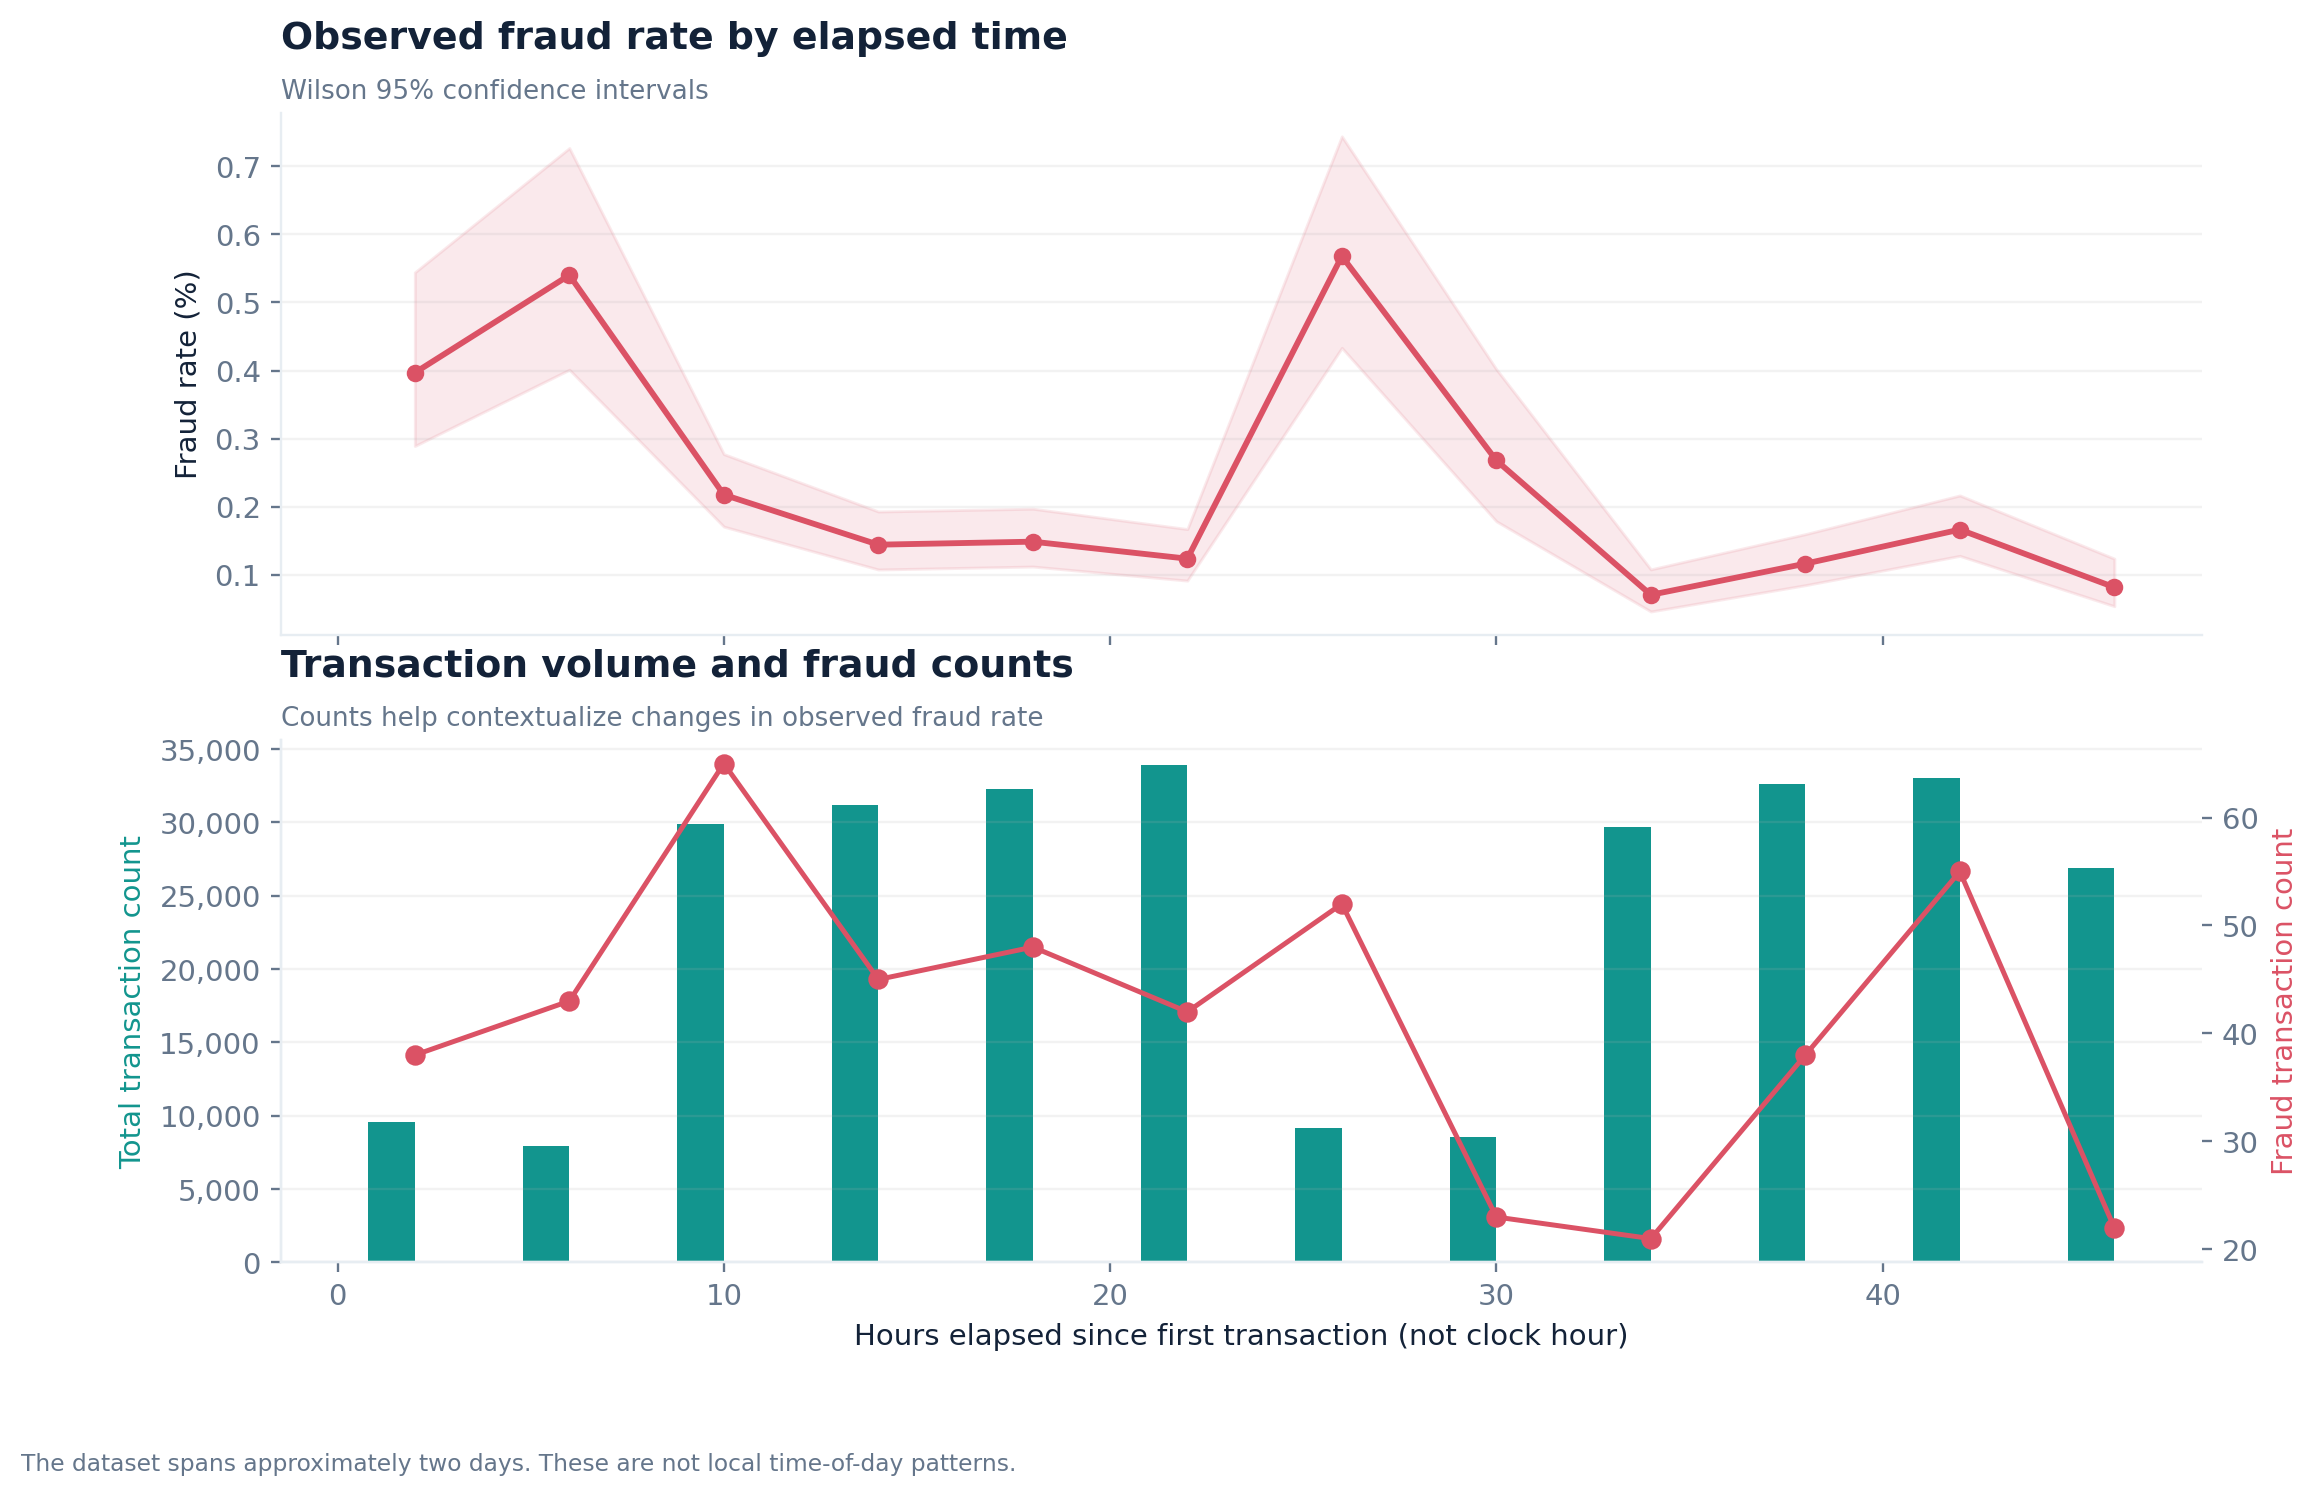

*Figure 5 · Observed fraud prevalence and transaction volume across four-hour elapsed-time intervals; short-run variation is not proof of periodicity.*

In [12]:
show_verified_figure("06_temporal_patterns.png", "Figure 5 · Observed fraud prevalence and transaction volume across four-hour elapsed-time intervals; short-run variation is not proof of periodicity.")

**RQ3 answer.** Fraud prevalence varies across this historical sample's elapsed-time windows. Because the observation window is short, we cannot infer recurring hour-of-day effects, seasonality, causal time effects, or future drift from this plot. Chronological **model validation** is a separate question examined in Notebook 03.

## 6 · RQ4 — Anonymized PCA feature separation

This is an *exploratory* class-conditional comparison. The project selected V14, V17, V12, V10 and V7 for visualization based on descriptive EDA. Their feature meanings are not available; lower or higher values must not be interpreted as identifiable customer behavior.

In [13]:
pca_features = ["V14", "V17", "V12", "V10", "V7"]
features = report_csv(EDA, "feature_by_class.csv", {"feature", "class", "median", "p05", "p95", "count"})
focus = features[features.feature.isin(pca_features)].copy()
assert len(focus) == 10 and set(focus["class"].astype(int)) == {0, 1}
focus["feature"] = pd.Categorical(focus.feature, categories=pca_features, ordered=True)
focus = focus.sort_values(["feature", "class"])
focus["class_name"] = focus["class"].map({0: "Legitimate", 1: "Fraud"})
display(focus[["feature", "class_name", "count", "p05", "median", "p95"]].style.format({
    "count": "{:,.0f}", "p05": "{:.3f}", "median": "{:.3f}", "p95": "{:.3f}"}))

,feature,class_name,count,p05,median,p95
0,V14,Legitimate,"284,315",-1.421,0.052,1.395
1,V14,Fraud,492,-14.224,-6.730,-0.073
2,V17,Legitimate,"284,315",-0.977,-0.065,1.274
3,V17,Fraud,492,-20.206,-5.303,2.717
4,V12,Legitimate,"284,315",-1.938,0.142,1.244
5,V12,Fraud,492,-15.592,-5.503,0.008
6,V10,Legitimate,"284,315",-1.327,-0.092,1.549
7,V10,Fraud,492,-15.014,-4.579,0.329
8,V7,Legitimate,"284,315",-1.421,0.041,1.408
9,V7,Fraud,492,-18.751,-3.034,1.298


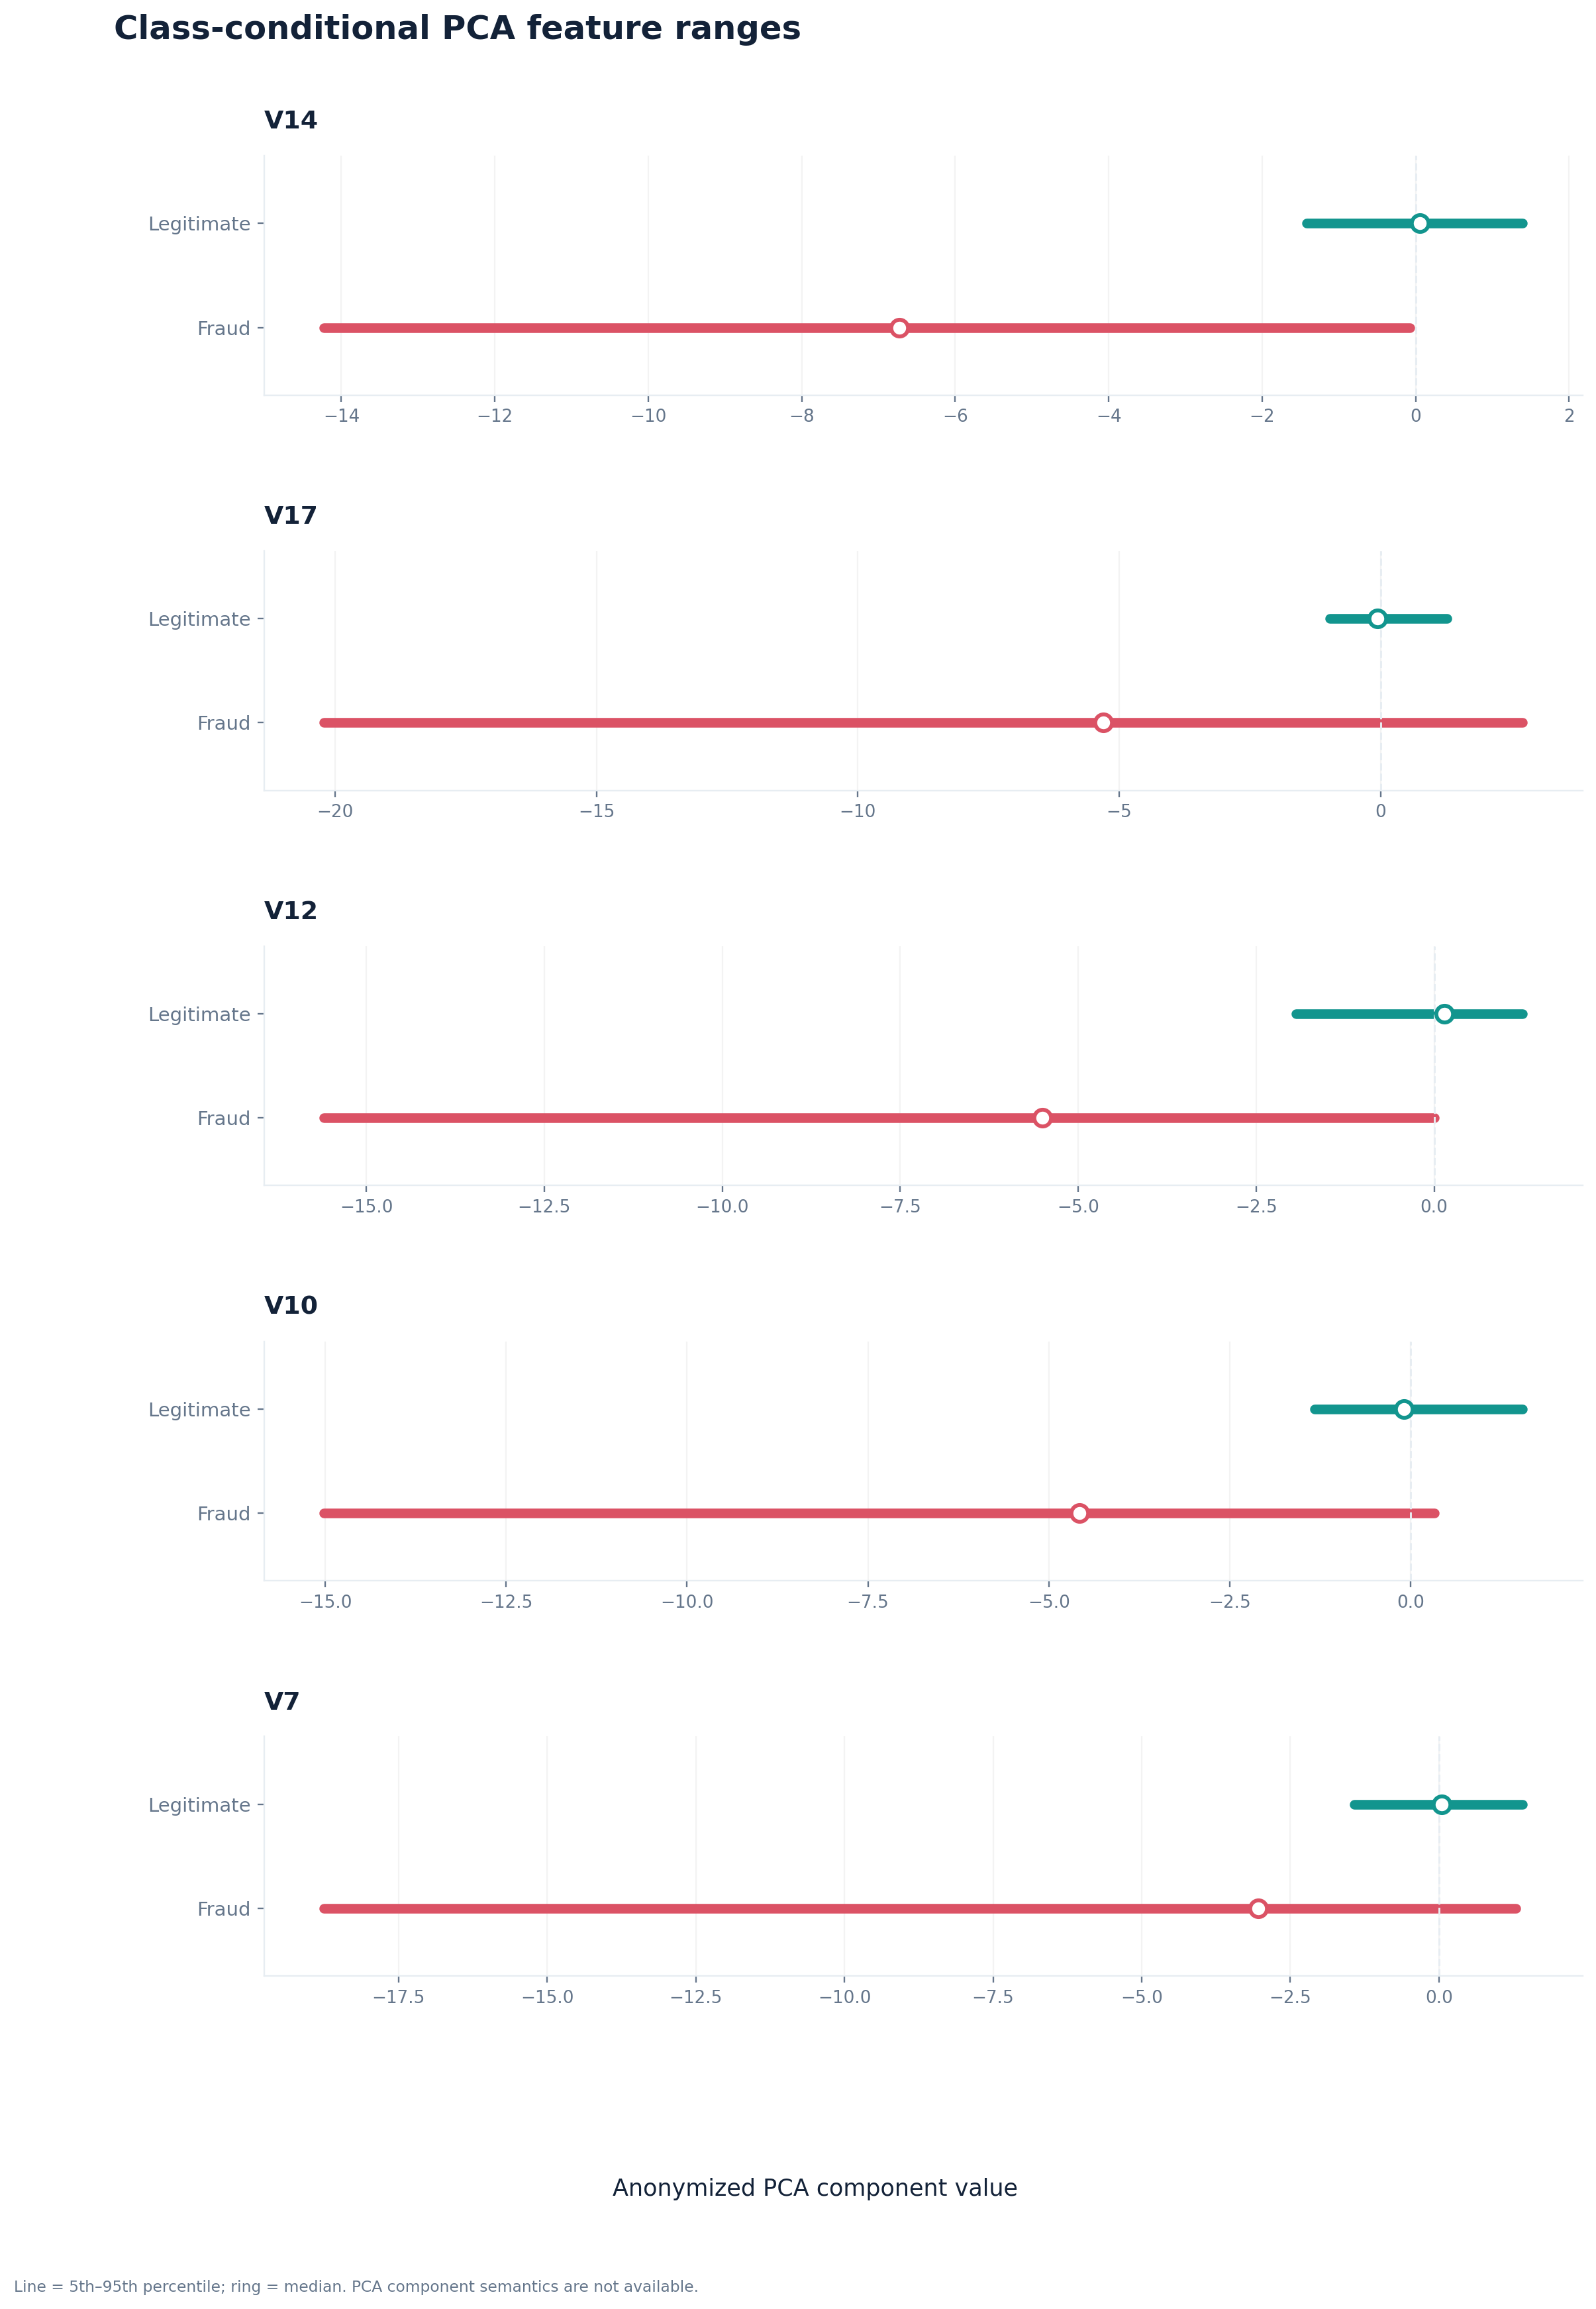

*Figure 6 · Class-conditional 5th–95th percentile ranges and medians for five anonymized features. Selected after exploratory inspection, not pre-registered.*

In [14]:
show_verified_figure("08_pca_class_comparison.png", "Figure 6 · Class-conditional 5th–95th percentile ranges and medians for five anonymized features. Selected after exploratory inspection, not pre-registered.")

**RQ4 answer.** The selected anonymized components show visibly different class-conditional ranges and medians in this sample. This justifies further statistical and predictive investigation, **not** a causal interpretation or a guarantee of future predictive importance. Selection based on the same data makes later significance tests exploratory.

## 7 · Evidence reconciliation and research handoff

A senior analyst should show that every headline result uses a consistent population and reconciles across modules. The following final checks compare the EDA and business outputs without rewriting their calculations.

In [15]:
business_kpis = report_csv(BUSINESS, "executive_kpis.csv", {
    "transactions", "fraud_cases", "recorded_fraud_value", "duplicate_rows", "fraud_rate_pct"
}).iloc[0]
business_bands = report_csv(BUSINESS, "amount_segment_exposure.csv", {
    "amount_band", "transactions", "fraud_cases", "fraud_amount", "share_of_fraud_value_pct"
}).sort_values("amount_band")
assert int(business_kpis.transactions) == transactions
assert int(business_kpis.fraud_cases) == frauds
assert int(business_kpis.duplicate_rows) == int(q["duplicate_rows_excluding_first"])
assert np.isclose(business_kpis.recorded_fraud_value, recorded_fraud_value, atol=.01)
assert np.isclose(business_kpis.fraud_rate_pct, fraud_prevalence, atol=1e-6)
assert len(business_bands) == len(bands)
assert np.array_equal(business_bands.transactions.to_numpy(), bands.total_txns.to_numpy())
assert np.array_equal(business_bands.fraud_cases.to_numpy(), bands.fraud_txns.to_numpy())
assert np.allclose(business_bands.fraud_amount.to_numpy(), bands.fraud_amount.to_numpy(), atol=.01)
print("PASS — all expected populations, class counts, duplicate counts, decile counts and fraud-value totals reconcile.")
print("No files were written or modified by this notebook.")

PASS — all expected populations, class counts, duplicate counts, decile counts and fraud-value totals reconcile.
No files were written or modified by this notebook.


### Research answers — concise synthesis

| Question | Supported observation | What it **does not** establish |
|---|---|---|
| **RQ1** · Prevalence | Fraud cases are ~0.173% of original transactions. | That a high-accuracy classifier detects fraud. |
| **RQ2** · Cases vs value | Lowest amount band dominates fraud **count**; highest band dominates recorded fraudulent **value**. | That reviewing large amounts prevents 78% of losses. |
| **RQ3** · Elapsed time | Observed rates differ across short elapsed-time windows. | Stable daily cycles or future drift. |
| **RQ4** · PCA components | Some anonymized distributions differ between labeled classes. | Interpretable feature semantics, causality or independent predictive contribution. |

**Next analytical steps**

1. **Notebook 02:** quantify uncertainty, effect sizes, multiple-testing correction and sensitivity to duplicate handling.
2. **Notebook 03:** compare leakage-controlled model experiments and evaluate later-period holdout errors and fraud-value recall.
3. **Notebook 04:** study constrained investigation budgets, ranking objectives, false alerts and hypothetical economics.

**Provenance note:** this notebook reads the original-population EDA/business reports, with exact duplicates retained. ML holdout results use a **different, deduplicated** population and should never be silently combined with these denominators.

**Final takeaway:** *Fraud case frequency and recorded fraudulent-value concentration diverge. This makes financial exposure a necessary companion to case-based fraud detection metrics.*